# Лабораторна робота 4: Дерева рішень та ансамблеві методи в багатокласовій класифікації за наявності пропущених значень

**Датасет:** Annealing (OpenML, `name='anneal', version=1`) — параметри промислового відпалу сталі.

**Мета:** порівняти Decision Tree, Random Forest і XGBoost на даних із пропусками, дослідити вплив способу обробки пропусків, коректно підібрати гіперпараметри за допомогою Optuna (без витоку даних), неупереджено оцінити моделі вкладеною крос-валідацією, статистично порівняти результати та інтерпретувати моделі (MDI, permutation importance, SHAP).

**Індивідуальний варіант:** номер у списку групи $N = 4$, отже $\text{SEED} = 42 + 4 = 46$.

**Структура ноутбука** повторює розділ «Хід роботи» методички (п. 3.1–3.8), далі йдуть висновок і відповіді на контрольні питання.


## Імпорт бібліотек і фіксація версій


In [1]:
import time
import warnings
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import scipy
import seaborn as sns
import shap
import sklearn
import xgboost
from IPython.display import display
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
from scipy import stats
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings('ignore', message='Skipping features without any observed values')
optuna.logging.set_verbosity(optuna.logging.WARNING)

STUDENT_NUMBER = 4
SEED = 42 + STUDENT_NUMBER
ALPHA = 0.05
MODEL_NAMES = ['DT', 'RF', 'XGB']
MODEL_LABELS = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}
BAR_COLOR = '#4C72B0'
INDICATOR_COLOR = '#C44E52'

np.random.seed(SEED)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (8, 4.5)

print('SEED =', SEED)
for module in [sklearn, xgboost, optuna, shap, pd, np, scipy]:
    print(f'{module.__name__:12s} {module.__version__}')


SEED = 46
sklearn      1.9.1
xgboost      3.2.0
optuna       5.0.0
shap         0.51.0
pandas       3.1.1
numpy        2.4.6
scipy        1.17.1


## 3.1. Первинний аналіз даних

### Завантаження

Використано версію OpenML з **898 спостереженнями** (не 798 із навчальної частини UCI). Вказано `parser='liac-arff'`: стандартний pandas-парсер у `fetch_openml` несумісний із pandas 3 на цьому файлі й падає з `TypeError`. На вміст даних це не впливає.


In [2]:
data = fetch_openml(name='anneal', version=1, as_frame=True, parser='liac-arff')
X_raw = data.data.rename(columns=unquote).copy()
y_raw = data.target.astype(str).rename('class')

categorical_columns = X_raw.select_dtypes(exclude='number').columns
X_raw[categorical_columns] = X_raw[categorical_columns].astype(object)
X_raw[categorical_columns] = X_raw[categorical_columns].where(X_raw[categorical_columns].notna(), np.nan)

print('Спостережень:', X_raw.shape[0], '| ознак:', X_raw.shape[1])
print('Типи ознак:', X_raw.dtypes.astype(str).value_counts().to_dict())
print('Числові:', X_raw.select_dtypes('number').columns.tolist())
print('Точних дублікатів рядків:', int(X_raw.duplicated().sum()))
X_raw.head()


Спостережень: 898 | ознак: 38
Типи ознак: {'object': 32, 'float64': 6}
Числові: ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']
Точних дублікатів рядків: 12


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,...,jurofm,s,p,shape,thick,width,len,oil,bore,packing
0,NaN,C,A,8.0,0.0,NaN,S,NaN,0.0,NaN,...,NaN,NaN,NaN,COIL,0.700,610.0,0.0,NaN,0,NaN
1,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,...,NaN,NaN,NaN,COIL,3.200,610.0,0.0,NaN,0,NaN
2,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,...,NaN,NaN,NaN,SHEET,0.700,1300.0,762.0,NaN,0,NaN
3,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,COIL,2.801,385.1,0.0,NaN,0,NaN
4,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,SHEET,0.801,255.0,269.0,NaN,0,NaN


### Частка пропусків, порожні та константні ознаки


,missing_share,values_without_nan,values_with_nan
p,1.0000,0,1
s,1.0000,0,1
jurofm,1.0000,0,1
corr,1.0000,0,1
marvi,1.0000,0,1
m,1.0000,0,1
bc,0.9989,1,2
exptl,0.9978,1,2
blue/bright/varn/clean,0.9933,3,4
phos,0.9922,1,2


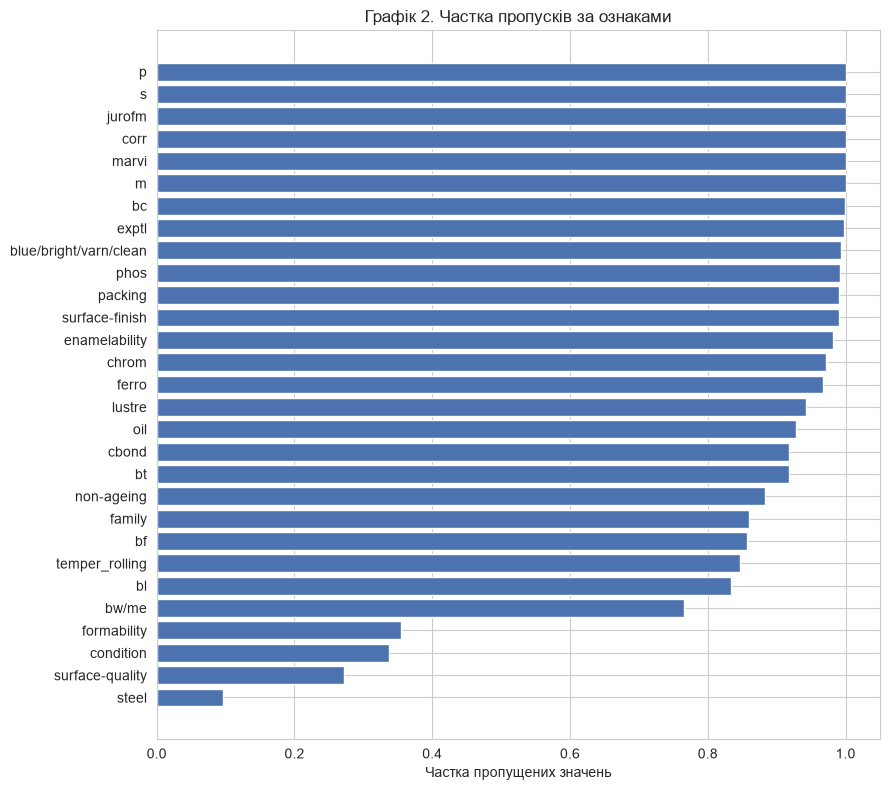

In [3]:
missing_share = X_raw.isna().mean().sort_values(ascending=False)
feature_profile = pd.DataFrame({
    'missing_share': missing_share.round(4),
    'values_without_nan': X_raw.nunique(dropna=True),
    'values_with_nan': X_raw.nunique(dropna=False),
}).loc[missing_share.index]
display(feature_profile)

plot_data = missing_share[missing_share > 0]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(plot_data.index[::-1], plot_data.values[::-1], color=BAR_COLOR)
ax.set_title('Графік 2. Частка пропусків за ознаками')
ax.set_xlabel('Частка пропущених значень')
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.show()


In [4]:
empty_features = feature_profile.index[feature_profile['values_without_nan'] == 0].tolist()
constant_features = feature_profile.index[
    (feature_profile['values_with_nan'] == 1) & (feature_profile['values_without_nan'] == 1)
].tolist()
value_or_missing = feature_profile.index[
    (feature_profile['values_without_nan'] == 1) & (feature_profile['values_with_nan'] == 2)
].tolist()

print('Повністю порожні (видаляємо):', empty_features)
print('Справді константні, без пропусків (видаляємо):', constant_features)
print(f'Формат «одне значення або пропуск», {len(value_or_missing)} ознак (залишаємо):')
print(value_or_missing)

X = X_raw.drop(columns=empty_features + constant_features)
print('\nОзнак після видалення:', X.shape[1])


Повністю порожні (видаляємо): ['p', 's', 'jurofm', 'corr', 'marvi', 'm']
Справді константні, без пропусків (видаляємо): ['product-type']
Формат «одне значення або пропуск», 13 ознак (залишаємо):
['bc', 'exptl', 'phos', 'surface-finish', 'chrom', 'ferro', 'lustre', 'cbond', 'bt', 'non-ageing', 'bf', 'temper_rolling', 'bl']

Ознак після видалення: 31


**Обґрунтування.** Видаляємо лише ознаки, які справді не несуть інформації: повністю порожні та сталі без жодного пропуску. Ознаки формату «одне значення або пропуск» залишаємо: `value_counts` бачить у них одне значення, але сама наявність значення є двійковою інформацією. Згідно з `anneal.names`, пропуск у цьому датасеті часто означає «не застосовно».

Для таких ознак спосіб обробки вирішальний. Імпутація модою перетворює їх на сталі, і у варіанті A сигнал зникає. У варіанті B його зберігає індикатор пропуску.


### Розподіл цільової змінної


,count,share_%
class,,
1,8,0.89
2,99,11.02
3,684,76.17
5,67,7.46
U,40,4.45


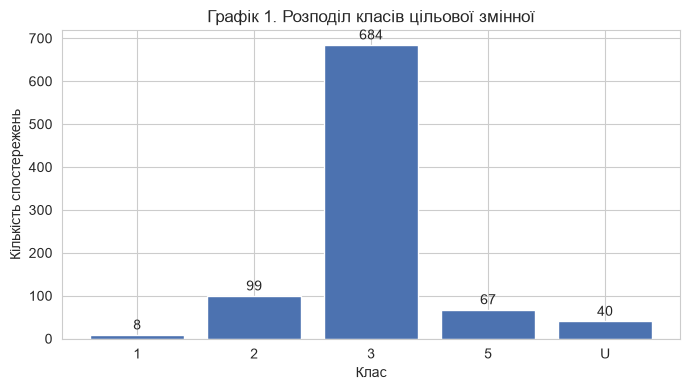

,Рівень,Мінімум об'єктів найменшого класу (оцінка знизу)
0,Увесь датасет,8
1,Train (80%),6
2,Train-частина блоку 5-fold,4
3,Train-частина внутрішнього 3-fold,2


In [5]:
class_counts = y_raw.value_counts().sort_index()
display(pd.DataFrame({
    'count': class_counts,
    'share_%': (class_counts / len(y_raw) * 100).round(2),
}))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=BAR_COLOR)
ax.bar_label(bars, padding=2)
ax.set_title('Графік 1. Розподіл класів цільової змінної')
ax.set_xlabel('Клас')
ax.set_ylabel('Кількість спостережень')
plt.tight_layout()
plt.show()

smallest = int(class_counts.min())
levels = pd.DataFrame([
    ('Увесь датасет', smallest),
    ('Train (80%)', int(np.floor(smallest * 0.8))),
    ('Train-частина блоку 5-fold', int(np.floor(np.floor(smallest * 0.8) * 0.8))),
    ('Train-частина внутрішнього 3-fold', int(np.floor(np.floor(np.floor(smallest * 0.8) * 0.8) * 2 / 3))),
], columns=['Рівень', 'Мінімум об\'єктів найменшого класу (оцінка знизу)'])
display(levels)


**Рішення щодо рідкісного класу.** Найменший клас `1` залишаємо: об'єднувати його немає з чим за змістом, а виключення приховало б найскладнішу частину задачі. Таблиця показує, що клас присутній на кожному рівні вкладеної крос-валідації, тож `StratifiedKFold` не видає попереджень, а XGBoost не падає через відсутній клас. Ціна рішення — велика дисперсія: на кількох об'єктах цього класу одна помилка помітно змінює macro F1.

Клас `4`, описаний у документації, у даних відсутній. Кодування `LabelEncoder` дає суцільні мітки $0,\dots,K-1$ саме для наявних класів.


### Аналіз механізму пропусків

Для 5 ознак із найбільшою часткою пропусків будуємо таблиці спряженості «пропуск / не пропуск» × клас. Частоти в таблицях малі, тому умови $\chi^2$ (очікувані частоти $\geq 5$) часто не виконуються. У таких випадках використовуємо точний критерій Фішера для таблиць $r\times c$ (р-значення оцінюється методом Монте-Карло). Якщо пропуски є MCAR, частка пропусків не повинна залежати від класу.


In [6]:
N_MECHANISM_FEATURES = 5
MIN_EXPECTED = 5

mechanism_features = (
    X.isna().mean().sort_values(ascending=False).head(N_MECHANISM_FEATURES).index.tolist()
)
mechanism_rows = []
for feature in mechanism_features:
    table = pd.crosstab(X[feature].isna().map({True: 'пропуск', False: 'не пропуск'}), y_raw)
    print(f'--- {feature} ---')
    display(table)
    chi2, chi2_p, _, expected = stats.chi2_contingency(table.to_numpy())
    use_chi2 = expected.min() >= MIN_EXPECTED
    if use_chi2:
        test_name, p_value = 'chi2', chi2_p
    else:
        fisher = stats.fisher_exact(
            table.to_numpy(),
            method=stats.MonteCarloMethod(n_resamples=9999, rng=SEED),
        )
        test_name, p_value = 'Fisher (MC)', fisher.pvalue
    shares = table.loc['пропуск'] / table.sum(axis=0)
    mechanism_rows.append({
        'Ознака': feature,
        'Частка пропусків': round(X[feature].isna().mean(), 3),
        'Мін. очікувана частота': round(expected.min(), 2),
        'chi2': round(chi2, 2),
        'Критерій': test_name,
        'p': p_value,
        'Частка пропусків за класами': shares.round(2).to_dict(),
    })
mechanism_table = pd.DataFrame(mechanism_rows)
mechanism_table['Незалежність відхилено (Бонферроні)'] = (
    mechanism_table['p'] < ALPHA / N_MECHANISM_FEATURES
)
display(mechanism_table)


--- bc ---


class,1,2,3,5,U
bc,,,,,
не пропуск,0,0,1,0,0
пропуск,8,99,683,67,40


--- exptl ---


class,1,2,3,5,U
exptl,,,,,
не пропуск,2,0,0,0,0
пропуск,6,99,684,67,40


--- blue/bright/varn/clean ---


class,1,2,3,5,U
blue/bright/varn/clean,,,,,
не пропуск,1,4,1,0,0
пропуск,7,95,683,67,40


--- phos ---


class,1,2,3,5,U
phos,,,,,
не пропуск,0,0,0,7,0
пропуск,8,99,684,60,40


--- packing ---


class,1,2,3,5,U
packing,,,,,
не пропуск,0,0,9,0,0
пропуск,8,99,675,67,40


,Ознака,Частка пропусків,Мін. очікувана частота,chi2,Критерій,p,Частка пропусків за класами,Незалежність відхилено (Бонферроні)
0,bc,0.999,0.01,0.31,Fisher (MC),1.0000,"{'1': 1.0, '2': 1.0, '3': 1.0, '5': 1.0, 'U': ...",False
1,exptl,0.998,0.02,223.00,Fisher (MC),0.0001,"{'1': 0.75, '2': 1.0, '3': 1.0, '5': 1.0, 'U':...",True
2,blue/bright/varn/clean,0.993,0.05,37.37,Fisher (MC),0.0004,"{'1': 0.88, '2': 0.96, '3': 1.0, '5': 1.0, 'U'...",True
3,phos,0.992,0.06,87.50,Fisher (MC),0.0001,"{'1': 1.0, '2': 1.0, '3': 1.0, '5': 0.9, 'U': ...",True
4,packing,0.990,0.08,2.84,Fisher (MC),0.7999,"{'1': 1.0, '2': 1.0, '3': 0.99, '5': 1.0, 'U':...",False


Ознаки з часткою пропусків понад 99% мають лише кілька відомих значень, тому критерій майже нічого про них не каже. Щоб висновок був змістовнішим, перевіряємо також ознаки із середньою часткою пропусків (від 5% до 90%). Тут частоти більші, і для більшості таблиць можна застосувати $\chi^2$.


In [7]:
moderate_features = X.columns[X.isna().mean().between(0.05, 0.90)]
moderate_features = X[moderate_features].isna().mean().sort_values(ascending=False).index
moderate_rows = []
for feature in moderate_features:
    table = pd.crosstab(X[feature].isna(), y_raw)
    chi2, chi2_p, _, expected = stats.chi2_contingency(table.to_numpy())
    if expected.min() >= MIN_EXPECTED:
        test_name, p_value = 'chi2', chi2_p
    else:
        fisher = stats.fisher_exact(
            table.to_numpy(),
            method=stats.MonteCarloMethod(n_resamples=9999, rng=SEED),
        )
        test_name, p_value = 'Fisher (MC)', fisher.pvalue
    shares = table.loc[True] / table.sum(axis=0)
    moderate_rows.append({
        'Ознака': feature,
        'Частка пропусків': round(X[feature].isna().mean(), 3),
        'Мін. очікувана частота': round(expected.min(), 2),
        'chi2': round(chi2, 1),
        'Критерій': test_name,
        'p': p_value,
        **{f'клас {c}': round(shares[c], 2) for c in shares.index},
    })
moderate_table = pd.DataFrame(moderate_rows)
moderate_table['Незалежність відхилено (Бонферроні)'] = (
    moderate_table['p'] < ALPHA / len(moderate_table)
)
display(moderate_table)


,Ознака,Частка пропусків,Мін. очікувана частота,chi2,Критерій,p,клас 1,клас 2,клас 3,клас 5,клас U,Незалежність відхилено (Бонферроні)
0,non-ageing,0.883,0.94,260.1,Fisher (MC),0.0001,1.00,1.00,0.92,0.28,1.00,True
1,family,0.860,1.12,463.7,Fisher (MC),0.0001,0.75,1.00,0.93,0.00,0.72,True
2,bf,0.856,1.15,32.2,Fisher (MC),0.0001,0.88,0.95,0.82,1.00,1.00,True
3,temper_rolling,0.847,1.22,227.1,Fisher (MC),0.0001,0.88,1.00,0.86,1.00,0.05,True
4,bl,0.834,1.33,27.1,Fisher (MC),0.0001,1.00,0.78,0.81,1.00,1.00,True
5,bw/me,0.765,1.88,13.7,Fisher (MC),0.0089,1.00,0.85,0.74,0.85,0.85,False
6,formability,0.354,2.83,136.2,Fisher (MC),0.0001,1.00,0.19,0.37,0.00,1.00,True
7,condition,0.337,2.70,151.0,Fisher (MC),0.0001,1.00,0.19,0.28,0.69,1.00,True
8,surface-quality,0.272,2.17,495.6,Fisher (MC),0.0001,1.00,0.90,0.12,1.00,0.00,True
9,steel,0.096,0.77,33.3,Fisher (MC),0.0001,0.00,0.08,0.09,0.28,0.00,True


**Висновок: пропуски не схожі на MCAR.** Серед п'яти ознак із найбільшою часткою пропусків незалежність відхилено для `exptl`, `blue/bright/varn/clean` і `phos`. Для `bc` і `packing` критерій не виявив залежності, але відомих значень там лише 1 і 9, тому потужність критерію низька, і це не доводить MCAR.

Для ознак із середньою часткою пропусків залежність дуже сильна (стовпець «Незалежність відхилено» другої таблиці). Найяскравіший приклад — `surface-quality`: значення відсутнє в усіх об'єктів класів `1` і `5`, у 90% об'єктів класу `2`, у 12% класу `3` і не пропущене в жодного об'єкта класу `U`. Так само `formability` завжди пропущена в класах `1` і `U` і ніколи не пропущена в класі `5`.

Отже, сам факт пропуску інформативний щодо класу. Це узгоджується з документацією, де частина пропусків означає «не застосовно», тобто є структурною. Розрізнити MAR і MNAR лише за цими даними не можна, але можна очікувати, що індикатори пропусків покращать якість. Це перевіряємо далі.


### Кодування цільової змінної


In [8]:
label_encoder = LabelEncoder()
y_enc = label_encoder.fit_transform(y_raw)
CLASS_NAMES = [str(c) for c in label_encoder.classes_]
print('Відповідність код -> клас:', dict(enumerate(CLASS_NAMES)))


Відповідність код -> клас: {0: '1', 1: '2', 2: '3', 3: '5', 4: 'U'}


## 3.2. Поділ даних і пайплайн обробки

Поділ стратифікований. Тестова вибірка використовується один раз — для фінальної оцінки в п. 3.6.

Вся обробка (імпутація, кодування, індикатори) міститься всередині `Pipeline`, тому в кожному блоці CV вона навчається лише на тренувальній частині.

**Відхилення від коду методички:** у `MissingIndicator` додано `error_on_new=False`. Без цього пайплайн падає, коли ознака з рідкісними пропусками не мала їх у тренувальному блоці, а у валідаційному вони є. Склад індикаторів усе одно визначається лише за тренувальною частиною блоку.

**Попередження imputer приховано навмисно.** Ознака `bc` має лише одне непорожнє значення на весь датасет, тому в тренувальних блоках вона зазвичай повністю порожня. `SimpleImputer` пропускає таку ознаку й щоразу видає `UserWarning` («Skipping features without any observed values»), що дало б тисячі однакових рядків. На результат це не впливає: ознака все одно не містить інформації.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
display(pd.DataFrame({
    'train': pd.Series(y_train).value_counts().sort_index().to_numpy(),
    'test': pd.Series(y_test).value_counts().sort_index().to_numpy(),
}, index=CLASS_NAMES))


def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append((
            'miss',
            MissingIndicator(features='missing-only', error_on_new=False),
            make_column_selector(),
        ))
    return ColumnTransformer(transformers)


def make_model(name: str, params: dict | None = None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)


def build_pipeline(name: str, with_indicators: bool = True, params: dict | None = None) -> Pipeline:
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params)),
    ])


for variant, flag in [('A', False), ('B', True)]:
    transformed = build_preprocessor(flag).fit_transform(X_train)
    print(f'Варіант {variant}: {transformed.shape[1]} ознак після обробки')


Train: (718, 31), Test: (180, 31)


,train,test
1,6,2
2,79,20
3,547,137
5,54,13
U,32,8


Варіант A: 52 ознак після обробки


Варіант B: 75 ознак після обробки


## 3.3. Базові моделі

Усі моделі й варіанти оцінюються на одному об'єкті `cv` (5 блоків × 3 повторення). `RepeatedStratifiedKFold` із цілим `random_state` дає однакові блоки при кожному виклику, і саме це робить можливим парне порівняння в п. 3.5.


In [10]:
SCORING = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
N_SPLITS, N_REPEATS = 5, 3
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

baseline_scores: dict[tuple[str, str], dict] = {}
baseline_seconds: dict[str, float] = {}
for variant, flag in [('A', False), ('B', True)]:
    for name in MODEL_NAMES:
        started = time.perf_counter()
        baseline_scores[(variant, name)] = cross_validate(
            build_pipeline(name, flag), X_train, y_train, cv=cv, scoring=SCORING
        )
        baseline_seconds[f'{variant}/{name}'] = time.perf_counter() - started


def format_scores(variant: str) -> pd.DataFrame:
    return pd.DataFrame({
        MODEL_LABELS[name]: {
            'Accuracy': '{:.4f} ± {:.4f}'.format(
                baseline_scores[(variant, name)]['test_acc'].mean(),
                baseline_scores[(variant, name)]['test_acc'].std(ddof=1),
            ),
            'Macro F1': '{:.4f} ± {:.4f}'.format(
                baseline_scores[(variant, name)]['test_f1m'].mean(),
                baseline_scores[(variant, name)]['test_f1m'].std(ddof=1),
            ),
            'Balanced accuracy': '{:.4f} ± {:.4f}'.format(
                baseline_scores[(variant, name)]['test_bacc'].mean(),
                baseline_scores[(variant, name)]['test_bacc'].std(ddof=1),
            ),
        }
        for name in MODEL_NAMES
    }).T


print('Таблиця 1. Крос-валідація, варіант A, типові параметри')
display(format_scores('A'))
print('Таблиця 2. Крос-валідація, варіант B, типові параметри')
display(format_scores('B'))
print('Час CV, с:', {key: round(value, 1) for key, value in baseline_seconds.items()})


Таблиця 1. Крос-валідація, варіант A, типові параметри


,Accuracy,Macro F1,Balanced accuracy
Decision Tree,0.9490 ± 0.0202,0.8400 ± 0.0766,0.8690 ± 0.0925
Random Forest,0.9555 ± 0.0224,0.9020 ± 0.0890,0.8978 ± 0.0958
XGBoost,0.9582 ± 0.0180,0.8849 ± 0.0889,0.8764 ± 0.0907


Таблиця 2. Крос-валідація, варіант B, типові параметри


,Accuracy,Macro F1,Balanced accuracy
Decision Tree,0.9902 ± 0.0098,0.9211 ± 0.0922,0.9389 ± 0.0957
Random Forest,0.9954 ± 0.0043,0.9525 ± 0.0831,0.9478 ± 0.0837
XGBoost,0.9912 ± 0.0072,0.9427 ± 0.0799,0.9345 ± 0.0805


Час CV, с: {'A/DT': 1.6, 'A/RF': 5.7, 'A/XGB': 37.2, 'B/DT': 1.8, 'B/RF': 6.2, 'B/XGB': 19.1}


**Порівняння варіантів.** Індикатори пропусків помітно покращили всі моделі: macro F1 зросла з 0.840 до 0.921 для DT, з 0.902 до 0.953 для RF і з 0.885 до 0.943 для XGBoost, а accuracy — приблизно з 0.95 до 0.99. У варіанті B найкращий результат має Random Forest.

Стандартне відхилення macro F1 (близько 0.08–0.09) значно більше за відхилення accuracy (менше 0.01 у варіанті B). Причина в рідкісному класі `1`: у тренувальній вибірці лише 6 його об'єктів, тож у валідаційному блоці їх 1 або 2, і одна помилка суттєво змінює macro F1. Це і є проявом «ефекту стелі».


## 3.4. Підбір гіперпараметрів за допомогою Optuna

Оптимізація виконується для варіанта B. У цільову функцію передається весь пайплайн, а не заздалегідь оброблені дані, тому імпутер не «бачить» валідаційних блоків.

Вкладена крос-валідація: зовнішня 5-блочна оцінює якість, внутрішня 3-блочна підбирає параметри лише на тренувальній частині кожного зовнішнього блоку.


In [11]:
N_TRIALS = 30


def suggest_params(trial: optuna.Trial, name: str) -> dict:
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical(
                'class_weight', [None, 'balanced', 'balanced_subsample']
            ),
        }
    return {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }


def tune(name: str, X_tr: pd.DataFrame, y_tr: np.ndarray, n_trials: int = N_TRIALS) -> optuna.Study:
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial: optuna.Trial) -> float:
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
    )
    study.optimize(objective, n_trials=n_trials)
    return study


In [12]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_results: dict[str, dict[str, list[float]]] = {}
nested_seconds: dict[str, float] = {}

for name in MODEL_NAMES:
    started = time.perf_counter()
    fold_scores: dict[str, list[float]] = {'f1m': [], 'acc': [], 'bacc': []}
    for fold, (tr_idx, va_idx) in enumerate(outer.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        predictions = model.predict(X_va)
        fold_scores['f1m'].append(f1_score(y_va, predictions, average='macro'))
        fold_scores['acc'].append(accuracy_score(y_va, predictions))
        fold_scores['bacc'].append(balanced_accuracy_score(y_va, predictions))
    nested_results[name] = fold_scores
    nested_seconds[name] = time.perf_counter() - started
    print(f"{name}: nested F1 = {np.mean(fold_scores['f1m']):.4f}, блоки: {np.round(fold_scores['f1m'], 4)}, {nested_seconds[name]:.0f} с")


DT: nested F1 = 0.9295, блоки: [0.9324 0.9714 0.9517 0.7921 1.    ], 49 с


RF: nested F1 = 0.9329, блоки: [0.9837 0.9837 0.9251 0.7855 0.9864], 431 с


XGB: nested F1 = 0.9384, блоки: [0.9837 0.9767 0.9324 0.7991 1.    ], 590 с


In [13]:
final_studies: dict[str, optuna.Study] = {}
for name in MODEL_NAMES:
    final_studies[name] = tune(name, X_train, y_train)

table3 = pd.DataFrame({
    MODEL_LABELS[name]: {
        'Вкладена CV, Macro F1': '{:.4f} ± {:.4f}'.format(
            np.mean(nested_results[name]['f1m']), np.std(nested_results[name]['f1m'], ddof=1)
        ),
        'Вкладена CV, Accuracy': '{:.4f} ± {:.4f}'.format(
            np.mean(nested_results[name]['acc']), np.std(nested_results[name]['acc'], ddof=1)
        ),
        'Вкладена CV, Balanced acc.': '{:.4f} ± {:.4f}'.format(
            np.mean(nested_results[name]['bacc']), np.std(nested_results[name]['bacc'], ddof=1)
        ),
        'best_value (вся train)': round(final_studies[name].best_value, 4),
        'best_value − вкладена F1': round(
            final_studies[name].best_value - np.mean(nested_results[name]['f1m']), 4
        ),
        'Вкладена F1 − базова F1 (B)': round(
            np.mean(nested_results[name]['f1m'])
            - baseline_scores[('B', name)]['test_f1m'].mean(), 4
        ),
    }
    for name in MODEL_NAMES
}).T
print('Таблиця 3. Вкладена крос-валідація, варіант B, після оптимізації, + best_value')
display(table3)

table4 = pd.DataFrame([
    {'Модель': MODEL_LABELS[name], 'Параметр': key, 'Значення': value}
    for name in MODEL_NAMES
    for key, value in final_studies[name].best_params.items()
])
table4['Значення'] = table4['Значення'].map(
    lambda value: round(value, 4) if isinstance(value, float) else str(value)
).astype(str)
print('Таблиця 4. Найкращі гіперпараметри, знайдені Optuna')
display(table4.set_index(['Модель', 'Параметр']))


Таблиця 3. Вкладена крос-валідація, варіант B, після оптимізації, + best_value


,"Вкладена CV, Macro F1","Вкладена CV, Accuracy","Вкладена CV, Balanced acc.",best_value (вся train),best_value − вкладена F1,Вкладена F1 − базова F1 (B)
Decision Tree,0.9295 ± 0.0808,0.9889 ± 0.0079,0.9532 ± 0.0870,0.8964,-0.0331,0.0084
Random Forest,0.9329 ± 0.0863,0.9875 ± 0.0059,0.9246 ± 0.0827,0.8979,-0.035,-0.0196
XGBoost,0.9384 ± 0.0818,0.9930 ± 0.0049,0.9282 ± 0.0806,0.8932,-0.0451,-0.0044


Таблиця 4. Найкращі гіперпараметри, знайдені Optuna


Значення
Модель        Параметр                             
Decision Tree max_depth                          17
              min_samples_split                   3
              min_samples_leaf                    1
              class_weight                 balanced
Random Forest n_estimators                      100
              max_depth                          22
              min_samples_leaf                    1
              max_features                     sqrt
              class_weight       balanced_subsample
XGBoost       n_estimators                       91
              max_depth                           6
              learning_rate                  0.2631
              subsample                      0.7806
              colsample_bytree               0.8316
              min_child_weight               1.5815

**Вкладена CV проти `best_value`.** Методичка очікує, що `best_value` буде оптимістичним, але тут він **нижчий** за вкладену оцінку: 0.896 проти 0.930 (DT), 0.898 проти 0.933 (RF), 0.893 проти 0.938 (XGBoost). Це не суперечить теорії, бо ці дві величини вимірюють не одне й те саме:
- `best_value` обчислюється на 3 блоках, тому модель навчається на 2/3 даних, а у вкладеній CV зовнішній блок навчається на 4/5;
- у 3-блочному поділі модель бачить лише 4 об'єкти класу `1`, тому цей клас класифікується гірше.

Песимізм через менший обсяг навчання тут переважив оптимізм через вибір максимуму. `best_value` усе одно не можна подавати як оцінку якості: він залежить від кількості блоків і містить зміщення відбору. Неупередженою оцінкою є вкладена CV.

**Великий розкид між блоками.** У четвертому зовнішньому блоці всі три моделі дають приблизно 0.79–0.80, а в інших — від 0.925 до 1.00. Таке спільне падіння узгоджується з помилкою на єдиному об'єкті рідкісного класу: тоді F1 цього класу дорівнює 0, а macro F1 падає приблизно на 0.2.

**Приріст після оптимізації** малий і не виходить за межі розкиду: +0.008 для DT, −0.004 для XGBoost, −0.020 для RF. На цьому датасеті типові параметри дерев уже близькі до оптимальних. Знайдені параметри це підтверджують: для DT і RF `min_samples_leaf = 1` і глибина, що фактично не обмежує дерево; головна зміна — `class_weight` із балансуванням.


### Графіки оптимізації


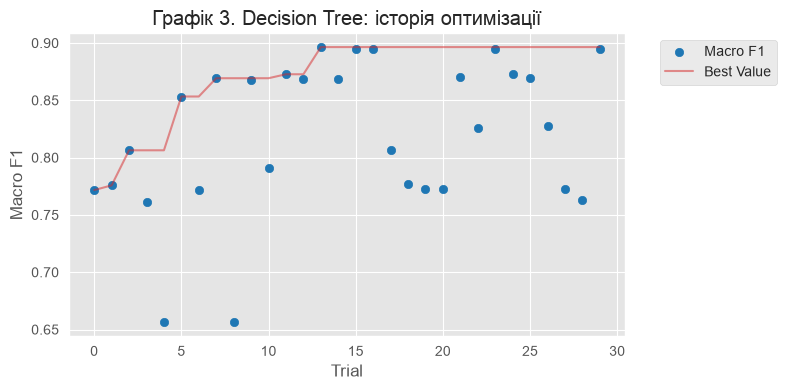

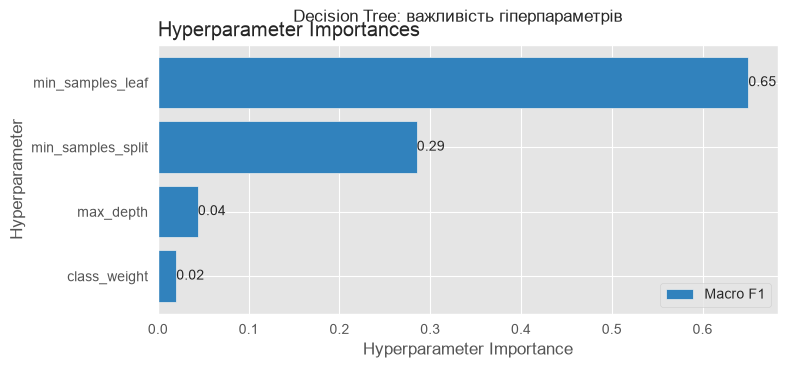

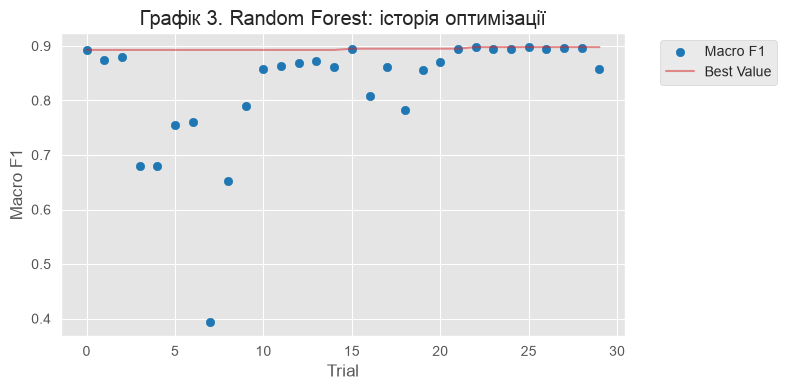

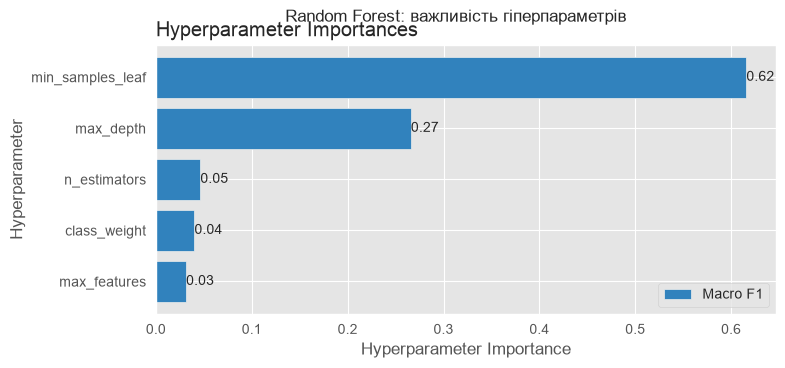

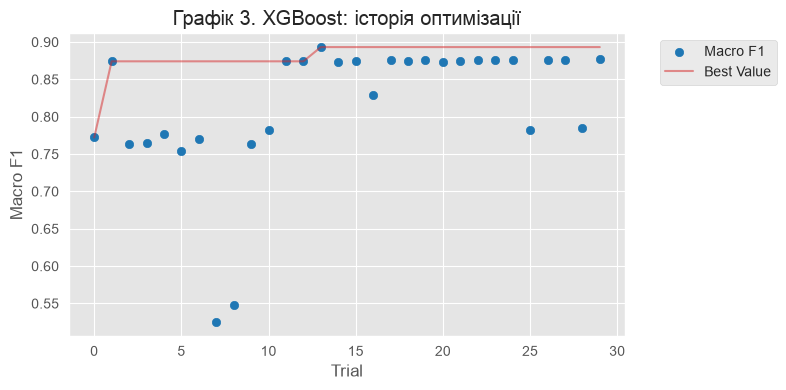

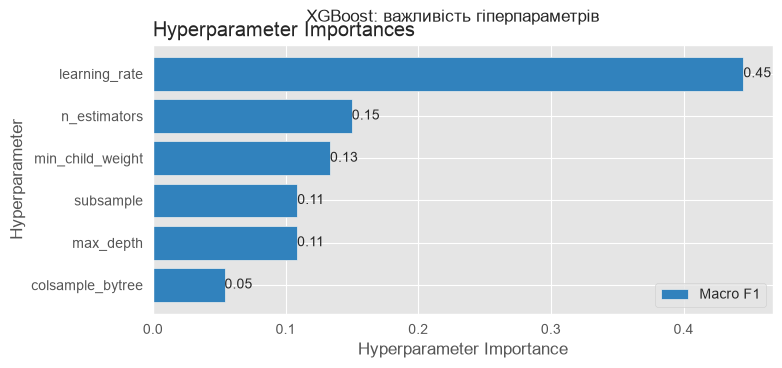

In [14]:
for name in MODEL_NAMES:
    history_axis = plot_optimization_history(final_studies[name], target_name='Macro F1')
    history_axis.set_title(f'Графік 3. {MODEL_LABELS[name]}: історія оптимізації')
    history_axis.figure.set_size_inches(8, 4)
    importance_axis = plot_param_importances(final_studies[name], target_name='Macro F1')
    importance_axis.set_title('')
    importance_axis.figure.suptitle(f'{MODEL_LABELS[name]}: важливість гіперпараметрів')
    importance_axis.figure.set_size_inches(8, 3.5)
    plt.show()

plt.style.use('default')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100


**Коментар до графіків.** Пошук зійшовся: для DT і XGBoost найкраще значення досягнуто приблизно на спробі № 13, а RF уже на першій спробі отримав близько 0.89 і далі майже не покращувався. В усіх моделях кращі спроби виходять на плато близько 0.87–0.90. Найважливіші параметри для DT і RF — `min_samples_leaf` (0.65 і 0.62), бо великий мінімальний лист не дає виділити рідкісний клас. Для XGBoost найважливіший `learning_rate` (0.45). Оцінки важливості ґрунтуються лише на 30 спробах, тому є наближеними.


### Фінальні моделі

Навчаємо кожну модель на всій тренувальній вибірці з параметрами з таблиці 4 і зберігаємо у `models/`.


In [15]:
MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

final_models: dict[str, Pipeline] = {}
for name in MODEL_NAMES:
    final_models[name] = build_pipeline(name, True, final_studies[name].best_params).fit(X_train, y_train)
    joblib.dump(final_models[name], MODELS_DIR / f'{name}.joblib')
print('Збережено:', sorted(path.name for path in MODELS_DIR.glob('*.joblib')))


Збережено: ['DT.joblib', 'RF.joblib', 'XGB.joblib']


## 3.5. Статистичне порівняння

Скоригований t-тест Надо–Бенджіо на однакових блоках із п. 3.3:

$$t = \frac{\bar d}{\sqrt{\hat\sigma_d^2\left(\frac{1}{kr} + \frac{n_{test}}{n_{train}}\right)}},\qquad df = kr - 1.$$

Для $k=5$ маємо $n_{test}/n_{train} = 1/4$, тож поправка значно більша за звичайний доданок $1/(kr) = 1/15$. Рівень значущості $\alpha = 0.05$.


In [16]:
def nadeau_bengio_ttest(
    scores_a: np.ndarray, scores_b: np.ndarray, k: int = N_SPLITS, r: int = N_REPEATS
) -> tuple[float, float, float]:
    differences = np.asarray(scores_a) - np.asarray(scores_b)
    mean_difference = differences.mean()
    variance = differences.var(ddof=1)
    if variance == 0:
        return float(mean_difference), 0.0, 1.0
    correction = 1 / (k * r) + 1 / (k - 1)
    t_value = mean_difference / np.sqrt(variance * correction)
    p_value = 2 * stats.t.sf(np.abs(t_value), df=k * r - 1)
    return float(mean_difference), float(t_value), float(p_value)


def comparison_row(title: str, scores_a: np.ndarray, scores_b: np.ndarray) -> dict:
    mean_difference, t_value, p_value = nadeau_bengio_ttest(scores_a, scores_b)
    if p_value >= ALPHA:
        verdict = 'різниця незначуща'
    else:
        verdict = 'значуща, перше краще' if mean_difference > 0 else 'значуща, друге краще'
    return {
        'Порівняння': title,
        'd̄': round(mean_difference, 4),
        't': round(t_value, 3),
        'p': round(p_value, 4),
        'Висновок (α = 0.05)': verdict,
    }


comparison_rows = [
    comparison_row(
        f'{MODEL_LABELS[name]}: B − A',
        baseline_scores[('B', name)]['test_f1m'],
        baseline_scores[('A', name)]['test_f1m'],
    )
    for name in MODEL_NAMES
]
ranked_b = sorted(
    MODEL_NAMES, key=lambda name: baseline_scores[('B', name)]['test_f1m'].mean(), reverse=True
)
comparison_rows.append(comparison_row(
    f'Варіант B: {MODEL_LABELS[ranked_b[0]]} − {MODEL_LABELS[ranked_b[1]]}',
    baseline_scores[('B', ranked_b[0])]['test_f1m'],
    baseline_scores[('B', ranked_b[1])]['test_f1m'],
))
print('Таблиця 5. Результати статистичного порівняння (Macro F1)')
display(pd.DataFrame(comparison_rows))


Таблиця 5. Результати статистичного порівняння (Macro F1)


,Порівняння,d̄,t,p,Висновок (α = 0.05)
0,Decision Tree: B − A,0.0811,1.628,0.1258,різниця незначуща
1,Random Forest: B − A,0.0505,2.890,0.0119,"значуща, перше краще"
2,XGBoost: B − A,0.0578,1.620,0.1275,різниця незначуща
3,Варіант B: Random Forest − XGBoost,0.0097,0.841,0.4145,різниця незначуща


**Результат тесту.** Значущим виявилось лише покращення Random Forest від індикаторів (p = 0.012). Для DT і XGBoost середній приріст навіть більший (0.081 і 0.058 проти 0.051), але розкид різниць теж більший, тому p ≈ 0.13 і нульову гіпотезу не відхилено. Це не означає відсутності ефекту: скоригований тест консервативний, а на 15 перетинних блоках із рідкісним класом дисперсія велика. Послідовний напрям різниці в усіх моделях і сильна залежність пропусків від класу теж свідчать на користь індикаторів.

Різниця між двома найкращими моделями варіанта B (RF і XGBoost) незначуща: $\bar d$ = 0.010, p = 0.41.


## 3.6. Фінальна оцінка на тестовій вибірці

Найкращу модель обираємо за вкладеною крос-валідацією ще до оцінки на тесті. Вибір за тестовими метриками зробив би тест частиною відбору.


In [17]:
best_name = max(MODEL_NAMES, key=lambda name: np.mean(nested_results[name]['f1m']))
print('Найкраща модель за вкладеною CV:', MODEL_LABELS[best_name])

test_predictions = {name: final_models[name].predict(X_test) for name in MODEL_NAMES}
table6 = pd.DataFrame({
    MODEL_LABELS[name]: {
        'Accuracy': accuracy_score(y_test, test_predictions[name]),
        'Macro F1': f1_score(y_test, test_predictions[name], average='macro'),
        'Balanced accuracy': balanced_accuracy_score(y_test, test_predictions[name]),
        'Помилок на тесті': int((test_predictions[name] != y_test).sum()),
    }
    for name in MODEL_NAMES
}).T
print('Таблиця 6. Якість фінальних моделей на тестовій вибірці')
display(table6.round(4))

print(f'classification_report, {MODEL_LABELS[best_name]}:')
print(classification_report(y_test, test_predictions[best_name], target_names=CLASS_NAMES, digits=4, zero_division=0))


Найкраща модель за вкладеною CV: XGBoost
Таблиця 6. Якість фінальних моделей на тестовій вибірці


,Accuracy,Macro F1,Balanced accuracy,Помилок на тесті
Decision Tree,0.9833,0.9707,0.9956,3.0
Random Forest,0.9833,0.9707,0.9956,3.0
XGBoost,0.9722,0.8979,0.8942,5.0


classification_report, XGBoost:
              precision    recall  f1-score   support

           1     1.0000    0.5000    0.6667         2
           2     0.9091    1.0000    0.9524        20
           3     0.9925    0.9708    0.9815       137
           5     1.0000    1.0000    1.0000        13
           U     0.8000    1.0000    0.8889         8

    accuracy                         0.9722       180
   macro avg     0.9403    0.8942    0.8979       180
weighted avg     0.9753    0.9722    0.9720       180



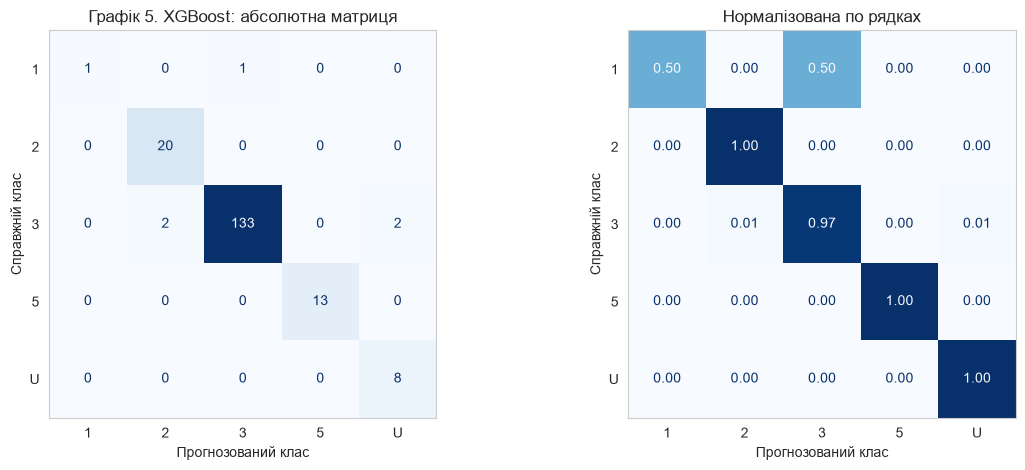

,Справжній,Прогноз,Кількість
0,1,3,1
1,3,2,2
2,3,U,2


In [18]:
absolute = confusion_matrix(y_test, test_predictions[best_name])
normalized = confusion_matrix(y_test, test_predictions[best_name], normalize='true')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(absolute, display_labels=CLASS_NAMES).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title(f'Графік 5. {MODEL_LABELS[best_name]}: абсолютна матриця')
ConfusionMatrixDisplay(normalized, display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f'
)
axes[1].set_title('Нормалізована по рядках')
for axis in axes:
    axis.grid(False)
    axis.set_xlabel('Прогнозований клас')
    axis.set_ylabel('Справжній клас')
plt.tight_layout()
plt.show()

errors = [
    {'Справжній': CLASS_NAMES[i], 'Прогноз': CLASS_NAMES[j], 'Кількість': int(absolute[i, j])}
    for i in range(len(CLASS_NAMES)) for j in range(len(CLASS_NAMES))
    if i != j and absolute[i, j] > 0
]
display(pd.DataFrame(errors) if errors else 'Помилок на тесті немає')


**Порівняння з крос-валідацією.** На тесті macro F1 становить 0.971 для DT і RF та 0.898 для XGBoost, хоча за вкладеною CV найкращим був XGBoost (0.938). Вибір моделі ми не змінюємо, бо інакше тест став би частиною відбору.

Розбіжність очікувана: у тесті лише 2 об'єкти класу `1`, тому одна помилка XGBoost знижує F1 цього класу до 0.667, а macro F1 приблизно на 0.067. Це майже вся різниця між моделями, яка насправді зводиться до 5 помилок проти 3 на 180 об'єктах. Висновку про перевагу DT чи RF ці дані не дають.

**Що плутається найчастіше.** XGBoost помилково відносить об'єкти більшого класу `3` до `2` (2 випадки) і до `U` (2 випадки), а один об'єкт класу `1` — до `3`. Найбільше страждають рідкісні класи: recall класу `1` дорівнює 0.50, precision класу `U` 0.80, класу `2` 0.91. Клас `5` визначається ідеально, бо його профіль пропусків дуже характерний (див. аналіз механізму).


## 3.7. Інтерпретація: важливість ознак

Для всіх трьох моделей рахуємо MDI на оброблених ознаках і permutation importance на тестовій вибірці на початкових ознаках. Для XGBoost `feature_importances_` за замовчуванням є середнім приростом (gain), тобто аналогом MDI.


/Users/miroslavzizin/IdeaProjects/ml/lab4/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/miroslavzizin/IdeaProjects/ml/lab4/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/miroslavzizin/IdeaProjects/ml/lab4/.venv/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

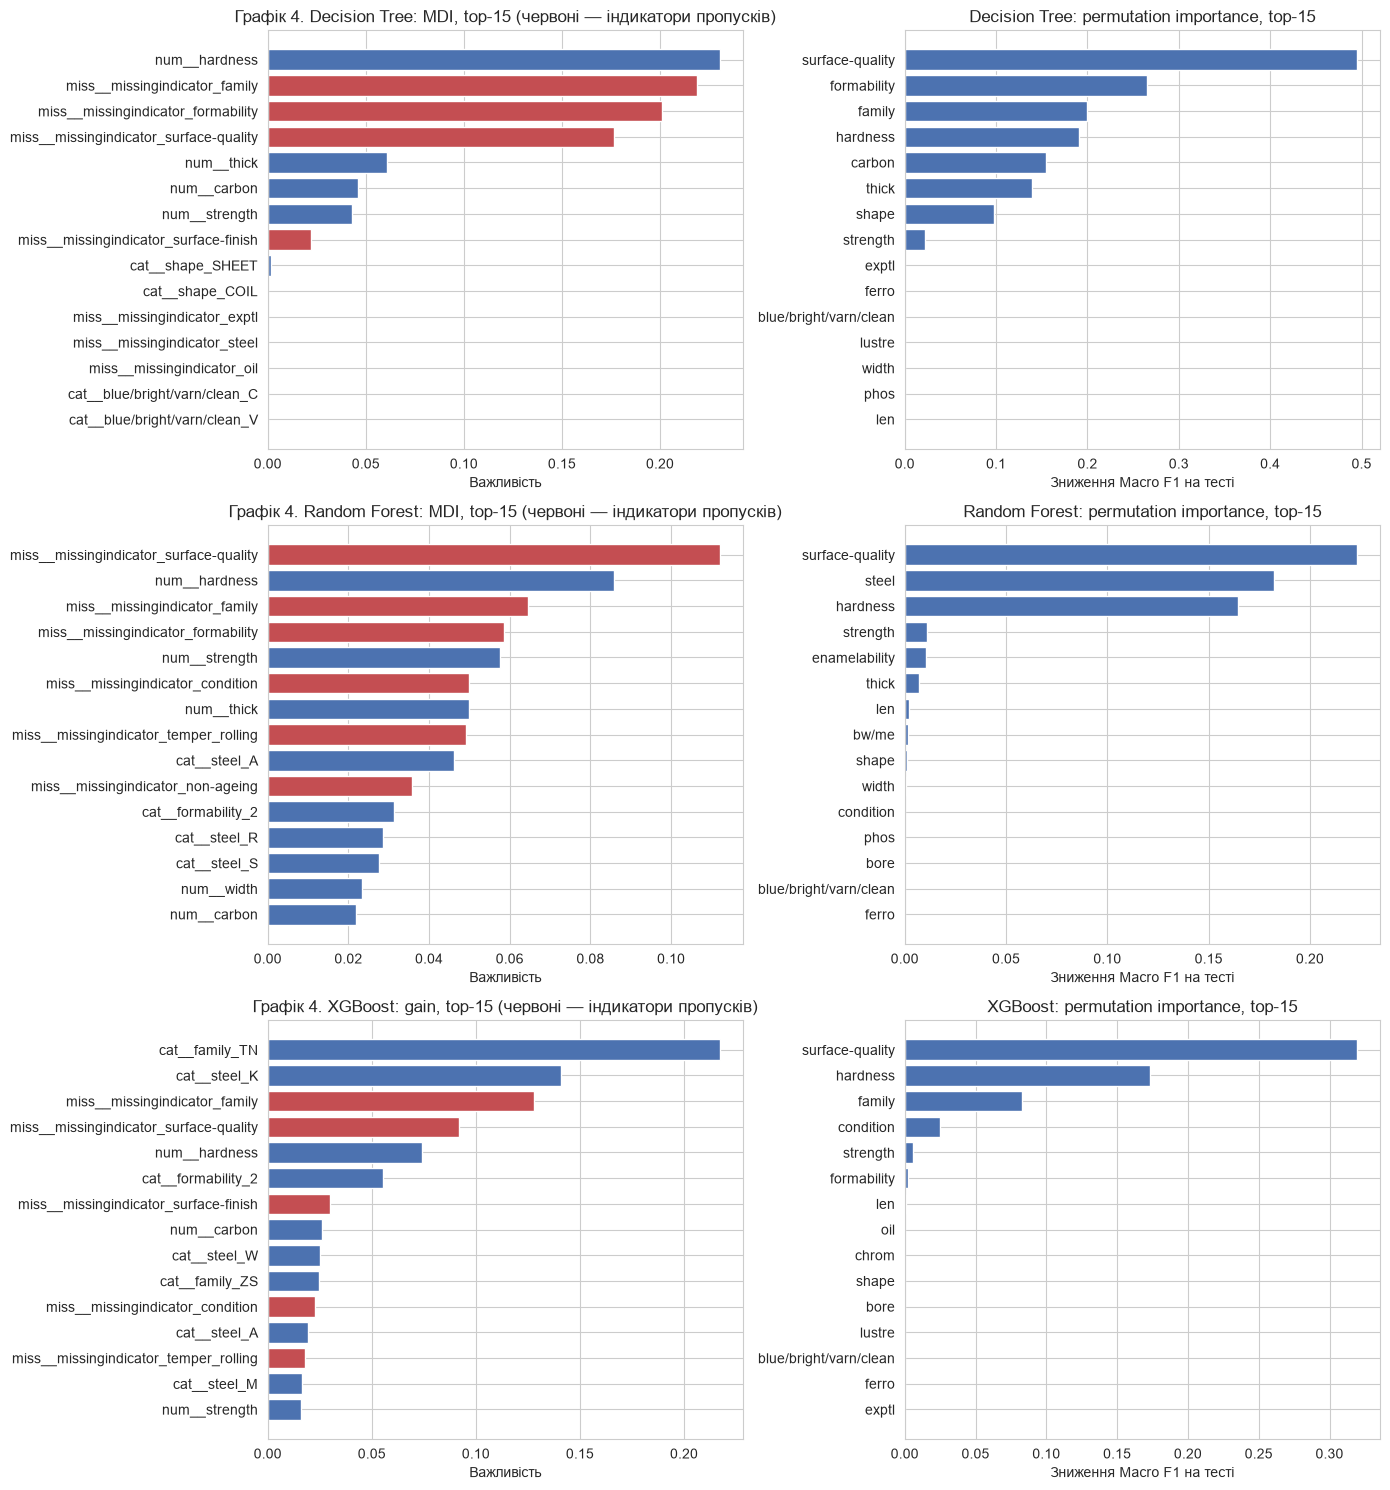

In [19]:
TOP_K = 15
N_PERMUTATION_REPEATS = 20


def mdi_table(name: str) -> pd.Series:
    pipeline = final_models[name]
    return pd.Series(
        pipeline.named_steps['clf'].feature_importances_,
        index=pipeline.named_steps['prep'].get_feature_names_out(),
    ).sort_values(ascending=False)


def original_feature(processed_name: str, columns: list[str]) -> str:
    prefix, _, rest = processed_name.partition('__')
    if prefix == 'miss':
        return rest.removeprefix('missingindicator_')
    if prefix == 'num':
        return rest
    return max((c for c in columns if rest == c or rest.startswith(f'{c}_')), key=len)


mdi = {name: mdi_table(name) for name in MODEL_NAMES}
permutation = {
    name: pd.Series(
        permutation_importance(
            final_models[name], X_test, y_test, scoring='f1_macro',
            n_repeats=N_PERMUTATION_REPEATS, random_state=SEED, n_jobs=1,
        ).importances_mean,
        index=X_test.columns,
    ).sort_values(ascending=False)
    for name in MODEL_NAMES
}

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
for row, name in enumerate(MODEL_NAMES):
    top_mdi = mdi[name].head(TOP_K)[::-1]
    colors = [INDICATOR_COLOR if 'missingindicator' in f else BAR_COLOR for f in top_mdi.index]
    axes[row, 0].barh(top_mdi.index, top_mdi.values, color=colors)
    importance_kind = 'gain' if name == 'XGB' else 'MDI'
    axes[row, 0].set_title(f'Графік 4. {MODEL_LABELS[name]}: {importance_kind}, top-{TOP_K} (червоні — індикатори пропусків)')
    axes[row, 0].set_xlabel('Важливість')
    top_permutation = permutation[name].head(TOP_K)[::-1]
    axes[row, 1].barh(top_permutation.index, top_permutation.values, color=BAR_COLOR)
    axes[row, 1].set_title(f'{MODEL_LABELS[name]}: permutation importance, top-{TOP_K}')
    axes[row, 1].set_xlabel('Зниження Macro F1 на тесті')
plt.tight_layout()
plt.show()


In [20]:
columns = X.columns.tolist()
agreement_rows = []
for name in MODEL_NAMES:
    top = mdi[name].head(TOP_K)
    grouped = mdi[name].groupby(lambda f: original_feature(f, columns)).sum()
    joined = pd.concat([grouped, permutation[name]], axis=1, keys=['mdi', 'perm']).dropna()
    top_mdi_set = set(grouped.sort_values(ascending=False).head(TOP_K).index)
    top_perm_set = set(permutation[name].head(TOP_K).index)
    agreement_rows.append({
        'Модель': MODEL_LABELS[name],
        'Індикаторів у top-15 MDI (важливість > 0)': int(
            (top[top.index.str.contains('missingindicator')] > 0).sum()
        ),
        'Частка MDI індикаторів (усі)': round(mdi[name][mdi[name].index.str.contains('missingindicator')].sum(), 3),
        'Spearman MDI ~ permutation': round(joined.corr(method='spearman').iloc[0, 1], 3),
        'Спільних у top-15': len(top_mdi_set & top_perm_set),
        'Ознак із permutation > 0': int((permutation[name] > 0).sum()),
    })
display(pd.DataFrame(agreement_rows))

ranks = pd.DataFrame({
    MODEL_LABELS[name]: mdi[name].groupby(lambda f: original_feature(f, columns)).sum()
    for name in MODEL_NAMES
}).fillna(0)
display(ranks.sort_values('Random Forest', ascending=False).head(12).round(3))

print('Індикатори пропусків у top-15 MDI:')
for name in MODEL_NAMES:
    indicators_in_top = mdi[name].head(TOP_K).filter(like='missingindicator').astype(float).round(3)
    print(' ', MODEL_LABELS[name], indicators_in_top[indicators_in_top > 0].to_dict())


,Модель,Індикаторів у top-15 MDI (важливість > 0),Частка MDI індикаторів (усі),Spearman MDI ~ permutation,Спільних у top-15,Ознак із permutation > 0
0,Decision Tree,4,0.618,0.943,10,8
1,Random Forest,6,0.457,0.295,9,11
2,XGBoost,5,0.321,0.390,7,7


,Decision Tree,Random Forest,XGBoost
surface-quality,0.177,0.149,0.102
steel,0.000,0.126,0.233
formability,0.201,0.107,0.066
family,0.219,0.088,0.370
hardness,0.231,0.086,0.074
condition,0.000,0.066,0.031
strength,0.043,0.058,0.016
thick,0.061,0.050,0.005
temper_rolling,0.000,0.049,0.018
non-ageing,0.000,0.036,0.000


Індикатори пропусків у top-15 MDI:
  Decision Tree {'miss__missingindicator_family': 0.219, 'miss__missingindicator_formability': 0.201, 'miss__missingindicator_surface-quality': 0.177, 'miss__missingindicator_surface-finish': 0.022}
  Random Forest {'miss__missingindicator_surface-quality': 0.112, 'miss__missingindicator_family': 0.064, 'miss__missingindicator_formability': 0.059, 'miss__missingindicator_condition': 0.05, 'miss__missingindicator_temper_rolling': 0.049, 'miss__missingindicator_non-ageing': 0.036}
  XGBoost {'miss__missingindicator_family': 0.128, 'miss__missingindicator_surface-quality': 0.092, 'miss__missingindicator_surface-finish': 0.03, 'miss__missingindicator_condition': 0.023, 'miss__missingindicator_temper_rolling': 0.018}


**Чи потрапили індикатори до top-15?** Так: 4 у DT, 6 у RF і 5 у XGBoost, а їхня сумарна частка становить 62%, 46% і 32%. У всіх трьох моделях серед лідерів `missingindicator_surface-quality` і `missingindicator_family`. Це прямо підтверджує аналіз механізму: пропуск цих ознак сильно залежить від класу, тому модель використовує сам факт пропуску, а не заповнене значення.

**Узгодженість MDI і permutation importance.** Обидва методи виділяють `surface-quality` (найвища permutation importance у всіх моделях: 0.49, 0.22, 0.32) і `hardness`. Кореляція Спірмена для RF і XGBoost невисока (0.30 і 0.39). Для DT вона становить 0.94, але цей показник завищений, бо більшість ознак в обох методах мають нульову важливість. Перестановка початкової ознаки міняє також її індикатор, тому для коректного порівняння MDI підсумовано за початковими ознаками.

**Зміщення MDI.** MDI рахується на тренувальних даних і віддає перевагу ознакам із багатьма унікальними значеннями, де більше можливих порогів. Приклад у RF: `thick` (50 унікальних значень) і `width` (68) мають MDI 0.050 і 0.023, а permutation importance близька до нуля. Permutation importance вимірює реальне зниження якості на тесті, але на малій кількості об'єктів рідкісних класів теж є шумною.

**Чому важливість різниться між моделями.** Одне дерево обирає на кожному кроці найкращу ознаку й ігнорує схожі: у DT `steel` має нульову MDI, тоді як у RF випадковий вибір ознак дає шанс і корельованим ознакам, і важливість розподіляється ширше. XGBoost будує дерева послідовно над залишками, тому наступні дерева використовують ознаки, що виправляють помилки попередніх, а його важливість рахується як gain, а не за Джині. Через це в XGBoost на перших місцях `family_TN` і `steel_K`.


## 3.8. Аналіз розбіжностей між моделями

Об'єкт розбіжності — це об'єкт, де прогнози трьох фінальних моделей не всі однакові. Якщо в тесті таких об'єктів менше трьох, таблицю доповнюємо об'єктами з train за out-of-fold прогнозами (`cross_val_predict`) і явно позначаємо їх у стовпці «Вибірка». Прогнози моделей на їхніх тренувальних даних не використовуються.


In [21]:
MIN_DISAGREEMENTS = 3


def disagreement_mask(predictions: dict[str, np.ndarray]) -> np.ndarray:
    stacked = np.vstack([predictions[name] for name in MODEL_NAMES])
    return ~(stacked == stacked[0]).all(axis=0)


def disagreement_rows(
    frame: pd.DataFrame, y_true: np.ndarray, predictions: dict[str, np.ndarray], source: str
) -> list[dict]:
    return [
        {
            'Об\'єкт': f'#{frame.index[position]}',
            'Вибірка': source,
            'Справжній клас': CLASS_NAMES[y_true[position]],
            **{MODEL_LABELS[name]: CLASS_NAMES[predictions[name][position]] for name in MODEL_NAMES},
        }
        for position in np.flatnonzero(disagreement_mask(predictions))
    ]


rows_table7 = disagreement_rows(X_test, y_test, test_predictions, 'test')
print('Об\'єктів розбіжності в тестовій вибірці:', len(rows_table7))

needs_out_of_fold = len(rows_table7) < MIN_DISAGREEMENTS
if needs_out_of_fold:
    oof_predictions = {
        name: cross_val_predict(
            build_pipeline(name, True, final_studies[name].best_params),
            X_train, y_train,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        )
        for name in MODEL_NAMES
    }
    oof_rows = disagreement_rows(X_train, y_train, oof_predictions, 'train, out-of-fold')
    print('Об\'єктів розбіжності у train (out-of-fold):', len(oof_rows))
    rows_table7 += oof_rows[: max(MIN_DISAGREEMENTS - len(rows_table7), 5)]

table7 = pd.DataFrame(rows_table7)
print('Таблиця 7. Об\'єкти розбіжностей між прогнозами моделей')
display(table7)


Об'єктів розбіжності в тестовій вибірці: 3
Таблиця 7. Об'єкти розбіжностей між прогнозами моделей


,Об'єкт,Вибірка,Справжній клас,Decision Tree,Random Forest,XGBoost
0,#406,test,1,1,1,3
1,#827,test,3,3,2,2
2,#746,test,3,2,3,2


### Детальний аналіз одного об'єкта

Обираємо об'єкт із тестової вибірки, а якщо там розбіжностей немає — з out-of-fold. Для out-of-fold об'єкта моделі перенавчаються на train без нього, щоб пояснення стосувалося прогнозу на невідомих даних.


In [22]:
test_disagreements = np.flatnonzero(disagreement_mask(test_predictions))
if len(test_disagreements):
    probabilities = np.stack([final_models[name].predict_proba(X_test) for name in MODEL_NAMES])
    spread = (probabilities.max(axis=0) - probabilities.min(axis=0)).max(axis=1)
    position = test_disagreements[np.argmax(spread[test_disagreements])]
    case_row = X_test.iloc[[position]]
    case_true = y_test[position]
    case_models = final_models
    case_source = 'test'
else:
    position = np.flatnonzero(disagreement_mask(oof_predictions))[0]
    case_row = X_train.iloc[[position]]
    case_true = y_train[position]
    keep = np.arange(len(X_train)) != position
    case_models = {
        name: build_pipeline(name, True, final_studies[name].best_params).fit(
            X_train.iloc[keep], y_train[keep]
        )
        for name in MODEL_NAMES
    }
    case_source = 'train, out-of-fold (моделі перенавчено без цього об\'єкта)'

print(f'Об\'єкт #{case_row.index[0]} | вибірка: {case_source} | справжній клас: {CLASS_NAMES[case_true]}')

reference_prep = case_models[best_name].named_steps['prep']
numeric_columns = reference_prep.transformers_[0][2]
categorical_selected = reference_prep.transformers_[1][2]
numeric_fill = dict(zip(numeric_columns, reference_prep.named_transformers_['num'].statistics_))
categorical_fill = dict(zip(
    categorical_selected,
    reference_prep.named_transformers_['cat'].named_steps['impute'].statistics_,
))
fill_values = {**numeric_fill, **categorical_fill}
indicator_columns = set(reference_prep.named_transformers_['miss'].get_feature_names_out(
    reference_prep.transformers_[2][2]
))

case_values = case_row.iloc[0]
case_table = pd.DataFrame({
    'Початкове значення': case_values.astype(object).where(case_values.notna(), 'пропуск'),
    'Пропущено': case_values.isna().map({True: 'так', False: ''}),
    'Заповнено значенням': [
        fill_values.get(c, '') if pd.isna(case_values[c]) else '' for c in case_values.index
    ],
    'Є індикатор': [
        'так' if f'missingindicator_{c}' in indicator_columns else '' for c in case_values.index
    ],
})
display(case_table)


Об'єкт #827 | вибірка: test | справжній клас: 3


,Початкове значення,Пропущено,Заповнено значенням,Є індикатор
family,пропуск,так,TN,так
steel,V,,,так
carbon,0.0,,,
hardness,0.0,,,
temper_rolling,пропуск,так,T,так
condition,S,,,так
formability,2,,,так
strength,0.0,,,
non-ageing,пропуск,так,N,так
surface-finish,пропуск,так,P,так


,P(клас 1),P(клас 2),P(клас 3),P(клас 5),P(клас U),Прогноз
Decision Tree,0.0000,0.0000,1.000,0.0000,0.0000,3
Random Forest,0.0000,0.5000,0.500,0.0000,0.0000,2
XGBoost,0.0007,0.9056,0.089,0.0021,0.0025,2


Decision Tree: прогноз 3, сума SHAP + base = 1.0000


,Оброблена ознака,Значення ознаки,SHAP
0,num__thick,3.2,0.5185
1,miss__missingindicator_family,1.0,0.2115
2,miss__missingindicator_surface-quality,1.0,-0.1066
3,num__hardness,0.0,0.0988
4,cat__shape_SHEET,1.0,0.0775


Random Forest: прогноз 2, сума SHAP + base = 0.5000


,Оброблена ознака,Значення ознаки,SHAP
0,miss__missingindicator_surface-quality,1.0,0.0948
1,cat__enamelability_1,1.0,-0.0809
2,cat__steel_A,0.0,0.0624
3,cat__enamelability_2,0.0,-0.0496
4,miss__missingindicator_condition,0.0,0.0473


XGBoost: прогноз 2, сума SHAP + base = 3.2449


,Оброблена ознака,Значення ознаки,SHAP
0,miss__missingindicator_surface-quality,1.0,1.5715
1,miss__missingindicator_condition,0.0,0.9500
2,num__strength,0.0,-0.4932
3,cat__steel_R,0.0,-0.4727
4,num__len,762.0,0.2822


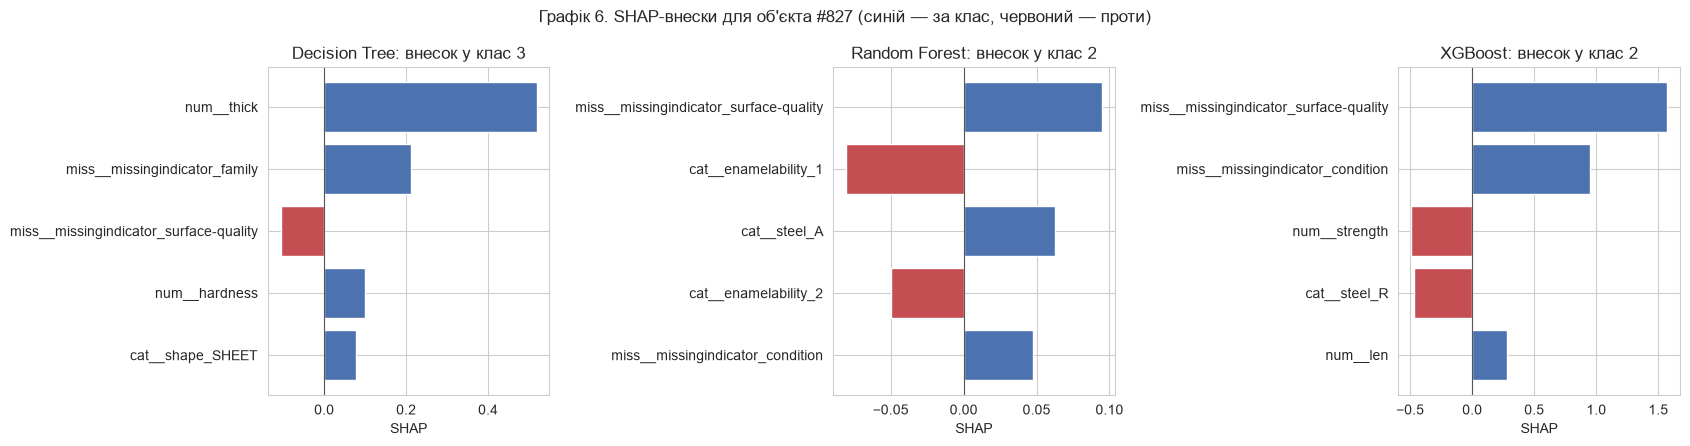

In [23]:
N_TOP_SHAP = 5

case_probabilities = pd.DataFrame(
    {MODEL_LABELS[name]: case_models[name].predict_proba(case_row)[0] for name in MODEL_NAMES},
    index=[f'P(клас {c})' for c in CLASS_NAMES],
).T
case_probabilities['Прогноз'] = [
    CLASS_NAMES[int(case_models[name].predict(case_row)[0])] for name in MODEL_NAMES
]
display(case_probabilities.round(4))

shap_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for axis, name in zip(axes, MODEL_NAMES):
    pipeline = case_models[name]
    processed = pipeline.named_steps['prep'].transform(case_row)
    feature_names = pipeline.named_steps['prep'].get_feature_names_out()
    explainer = shap.TreeExplainer(pipeline.named_steps['clf'])
    values = np.asarray(explainer.shap_values(processed))
    assert values.shape == (1, processed.shape[1], len(CLASS_NAMES)), values.shape
    predicted = int(pipeline.predict(case_row)[0])
    contributions = pd.Series(values[0, :, predicted], index=feature_names)
    top = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(N_TOP_SHAP)
    shap_tables[name] = pd.DataFrame({
        'Оброблена ознака': top.index,
        'Значення ознаки': pd.Series(processed[0], index=feature_names).reindex(top.index).round(3).to_numpy(),
        'SHAP': top.round(4).to_numpy(),
    })
    print(f'{MODEL_LABELS[name]}: прогноз {CLASS_NAMES[predicted]}, сума SHAP + base = {contributions.sum() + np.ravel(explainer.expected_value)[predicted]:.4f}')
    display(shap_tables[name])
    ordered = top[::-1]
    axis.barh(
        ordered.index, ordered.values,
        color=[BAR_COLOR if value >= 0 else INDICATOR_COLOR for value in ordered.values],
    )
    axis.axvline(0, color='#555555', linewidth=0.8)
    axis.set_title(f'{MODEL_LABELS[name]}: внесок у клас {CLASS_NAMES[predicted]}')
    axis.set_xlabel('SHAP')
fig.suptitle(f'Графік 6. SHAP-внески для об\'єкта #{case_row.index[0]} (синій — за клас, червоний — проти)')
plt.tight_layout()
plt.show()


**Детальний аналіз об'єкта #827** (справжній клас `3`). Правильно його класифікувало лише дерево рішень. Ймовірність класу `2`/`3`: DT 0.00/1.00, RF 0.50/0.50, XGBoost 0.91/0.09. Random Forest перебуває на самій межі двох класів, тож його прогноз `2` не є впевненим.

**Роль пропусків.** У цього об'єкта пропущено більшість категоріальних ознак, зокрема `surface-quality`, яку заповнено значенням `E`. Це значення не має фізичного змісту для цього об'єкта, і серед топ-5 SHAP-внесків жодної моделі заповнених значень немає. Натомість у RF і XGBoost найбільший внесок дає `missingindicator_surface-quality` на користь класу `2`. Це логічно: у датасеті ця ознака пропущена у 90% об'єктів класу `2` і лише в 12% об'єктів класу `3`. Відома `steel = V` разом із формою `SHEET` теж частіше трапляється в класі `2` (7 об'єктів проти 3).

**Жорсткі пороги проти усереднення.** Для DT той самий індикатор також свідчить проти класу `3` (внесок −0.11), але вирішальним є поріг за `thick = 3.2` (внесок +0.52). Товщину 3.2 в датасеті мають 54 об'єкти класу `3` і жодного об'єкта класу `2`. Одне дерево спирається на цей різкий поділ і отримує впевненість 1.00. Ансамблі усереднюють багато сигналів, і для них цей поріг не є вирішальним: `thick` не входить до їхніх топ-5.

**Висновок щодо розбіжності.** Причина — суперечливі ознаки в об'єкта, близького до межі між класами `2` і `3`. Правильна відповідь дерева не означає, що воно загалом надійніше: у цьому випадку спрацював один вдалий поріг, а загальна кількість помилок у DT і RF однакова.

**Масштаб SHAP:** для DT і RF внески виражені у шкалі ймовірностей, а для XGBoost у шкалі відступів (log-odds). Тому абсолютні значення між моделями порівнювати не можна, лише напрям і порядок ознак.


## Висновок

1. За вкладеною CV найкраща модель — XGBoost (macro F1 = 0.938 ± 0.082), але результат нестабільний: на тесті кращі DT і RF (0.971 проти 0.898), а різниця RF і XGBoost у CV незначуща (p = 0.41), тому статистично значущої переваги жодна модель не має.
2. Індикатори пропусків підвищили macro F1 усіх моделей на 0.05–0.08, хоча значущим цей ефект є лише для RF (p = 0.012).
3. Це узгоджується з аналізом механізму, бо пропуски залежать від класу й не схожі на MCAR, і з важливостями, бо до top-15 увійшло 4–6 індикаторів.
4. `best_value` виявився нижчим за вкладену оцінку на 0.033–0.045, бо 3-блочна CV навчається на меншій частині даних.
5. Отже, зміщення `best_value` може бути різним за напрямом, тому як оцінку якості він не годиться навіть тоді, коли не здається оптимістичним.
6. Найбільший приріст після оптимізації отримало дерево рішень (+0.008), але він у межах шуму, а в RF і XGBoost приросту немає, тож типові параметри тут уже близькі до оптимальних.
7. Найскладніший клас — `1`: лише 8 об'єктів у датасеті й recall 0.50 у XGBoost на тесті.
8. Також об'єкти великого класу `3` іноді плутаються з класами `2` і `U`, бо їхні профілі ознак частково перетинаються.
9. У тесті знайдено 3 об'єкти розбіжності зі 180, і аналіз #827 показав об'єкт на межі класів `2` і `3`: дерево вирішило справу одним порогом за `thick`, а ансамблі спиралися на індикатор пропуску й дали інший прогноз.
10. Для практичного використання доцільно обрати Random Forest: він має найвищу accuracy у варіанті B (0.995), єдиний статистично підтверджений виграш від індикаторів і менші обчислювальні витрати, ніж XGBoost.
11. Якщо головною вимогою є інтерпретованість, прийнятним варіантом є дерево рішень, хоча воно чутливіше до окремих порогів.
12. Усі оцінки отримано для SEED = 46, а через рідкісний клас вони мають значну дисперсію.


## Контрольні питання

**1. Випадковий ліс проти дерева.** Глибоке дерево має мале зміщення й велику дисперсію. Ліс усереднює багато дерев, зберігаючи приблизно те саме зміщення й зменшуючи дисперсію. Для $B$ дерев із дисперсією $\sigma^2$ і кореляцією $\rho$ дисперсія середнього дорівнює $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$. Перший доданок не зменшується зі зростанням $B$, тому важлива декореляція: бутстреп і випадковий вибір ознак у вузлах зменшують $\rho$.

**2. Бустинг і беггінг.** Беггінг навчає моделі паралельно на бутстреп-вибірках і переважно знижує дисперсію. Бустинг навчає їх послідовно, кожна виправляє помилки попередніх, і переважно знижує зміщення. До перенавчання зі зростанням кількості дерев схильніший бустинг, бо кожне нове дерево далі підганяється під залишки тренувальних даних. У беггінгу додавання дерев лише стабілізує середнє.

**3. Macro F1 і balanced accuracy.** Accuracy визначається великими класами: модель, що завжди прогнозує клас `3`, отримала б тут близько 0.76. Macro F1 і balanced accuracy надають кожному класу рівну вагу. Macro-усереднення F1 — це просте середнє за класами, weighted зважує їх за кількістю об'єктів і тому знову наближається до accuracy.

**4. MCAR, MAR, MNAR.** За MCAR пропуск не залежить від жодних даних, за MAR залежить лише від спостережуваних значень, за MNAR — від самого відсутнього значення чи неспостережуваних чинників. Індикатори найкорисніші, коли пропуск несе інформацію про ціль, тобто за MAR і MNAR, а також для структурних пропусків. Однозначно відрізнити MAR від MNAR за даними не можна, бо відсутні значення не спостерігаються; для цього потрібні додаткові припущення чи знання про предметну область.

**5. Витік даних.** Імпутація або кодування на всьому датасеті до поділу чи CV; передача в Optuna заздалегідь оброблених даних; використання тестової вибірки в цільовій функції; вибір моделі за тестом. Запобігання: уся обробка всередині `Pipeline`, у цільову функцію передається весь пайплайн, тест використовується один раз наприкінці.

**6. `best_value` і вкладена CV.** `best_value` — максимум серед шумних оцінок для багатьох конфігурацій, тому він зміщений угору: перемагає конфігурація, якій частково пощастило з блоками. У вкладеній CV внутрішній цикл підбирає параметри лише на тренувальній частині зовнішнього блоку, а зовнішній оцінює на даних, які не брали участі в підборі. У зовнішньому циклі ми оцінюємо не одну модель, а **всю процедуру навчання разом із підбором параметрів**.

**7. Тест Надо–Бенджіо.** Блоки CV мають спільні тренувальні дані, тому різниці на блоках корельовані, а незалежності, потрібної звичайному t-тесту, немає. Він занижує дисперсію і дає забагато хибних спрацювань. Поправка замінює множник $\frac{1}{kr}$ на $\frac{1}{kr} + \frac{n_{test}}{n_{train}}$, що враховує цю кореляцію.

**8. MDI і permutation importance.** MDI — сумарне зменшення неоднорідності за ознакою на тренувальних даних; швидка, але зміщена до ознак із багатьма значеннями. Permutation importance вимірює падіння метрики при перемішуванні ознаки на відкладених даних і не залежить від будови моделі. Корельовані ознаки поділяють MDI між собою, тому важливість кожної занижена; при перестановці одної ознаки модель може використати її корельовану пару, тому permutation importance теж занижує обидві.

**9. SHAP.** SHAP-значення — це значення Шеплі з теорії ігор, тобто середній внесок ознаки за всіма можливими порядками її додавання. Властивість адитивності: сума внесків усіх ознак і базового значення дорівнює прогнозу для об'єкта. Локальне пояснення показує, чому прийнято конкретний прогноз, а глобальна важливість описує поведінку моделі в цілому, наприклад через середнє абсолютне SHAP-значення.

**10. Sparsity-aware split finding у XGBoost.** Для кожного вузла алгоритм пробує спрямувати всі об'єкти з пропуском ліворуч, а потім праворуч, і обирає напрям із більшим приростом. Пороги перебираються лише за об'єктами з відомими значеннями. Отже, напрям для пропуску навчається з даних, а обчислення залежать лише від кількості непропущених значень.

**11. Переваги Optuna.** На відміну від `GridSearchCV` і `RandomizedSearchCV`, TPE-семплер використовує результати попередніх спроб і концентрує пошук у перспективних областях. Це ефективніше для обмеженого бюджету й великого простору параметрів. Прунінг достроково зупиняє безперспективні спроби, економлячи час. Також Optuna підтримує умовні простори параметрів, визначені прямо в коді.

## Література

1. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. 2nd ed. Springer, 2009.
2. Breiman L. Random Forests // Machine Learning. 2001. Vol. 45, No. 1. P. 5–32.
3. Chen T., Guestrin C. XGBoost: A Scalable Tree Boosting System // KDD '16. 2016. P. 785–794.
4. Pedregosa F. et al. Scikit-learn: Machine Learning in Python // JMLR. 2011. Vol. 12. P. 2825–2830.
5. Rubin D. B. Inference and Missing Data // Biometrika. 1976. Vol. 63, No. 3. P. 581–592.
6. Akiba T. et al. Optuna: A Next-generation Hyperparameter Optimization Framework // KDD '19. 2019. P. 2623–2631.
7. Josse J. et al. On the consistency of supervised learning with missing values // arXiv:1902.06931. 2019.
8. Cawley G. C., Talbot N. L. C. On over-fitting in model selection and subsequent selection bias in performance evaluation // JMLR. 2010. Vol. 11. P. 2079–2107.
9. Nadeau C., Bengio Y. Inference for the Generalization Error // Machine Learning. 2003. Vol. 52, No. 3. P. 239–281.
10. Strobl C. et al. Bias in random forest variable importance measures // BMC Bioinformatics. 2007. Vol. 8. Article 25.
11. Lundberg S. M., Lee S.-I. A Unified Approach to Interpreting Model Predictions // NeurIPS 2017. Vol. 30. P. 4765–4774.
12. Lundberg S. M. et al. From local explanations to global understanding with explainable AI for trees // Nature Machine Intelligence. 2020. Vol. 2, No. 1. P. 56–67.
